# **Assignment 7: Binary Classification Methods**

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

# Abstract

In this assignment, we are going to predict wether a patient has cancer or not..

# Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install arabic_reshaper

In [ ]:
!pip install python-bidi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 286.8/286.8 kB 7.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from matplotlib.category import UnitData

# We need these libraries for Farsi writting
import arabic_reshaper
import bidi.algorithm

wr.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

## **Read dataset**

Here, we are going to perform a regression task on [Breaest Cancer](https://www.kaggle.com/datasets/yasserh/breast-cancer-dataset) dataset. (The dataset is put in the same directory as this jupyter file.

first let's read it :

In [ ]:
# df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW7/breast-cancer.csv")
df_org=pd.read_csv("breast-cancer.csv")

Now, let's have a general look at the the data.

In [ ]:
df = df_org
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Here our target variable is 'diagnosis'. What we want to do is to predict wether our patient has cancer or not (M - Malignant B - Benign).

We have an id column. we delete this as it may affect the performance of our models.

In [ ]:
if 'id' in df.columns:
  df = df.drop('id', axis=1)

Then we convert the 'diagnosis' to a numerical variable:


Let's check the datatype of columns:

In [ ]:
# prompt: convert 'diagnosis' to numerical 0 and 1. don't use map()

df['diagnosis'] = (df['diagnosis'] == 'M').astype(int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

Also, let's have a look at statistics of numerical features.

In [ ]:
df.describe()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


is there any null value? No!

In [ ]:
print(df.isnull().sum())

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


And now, let's plot correlation heatmap of numerical features.

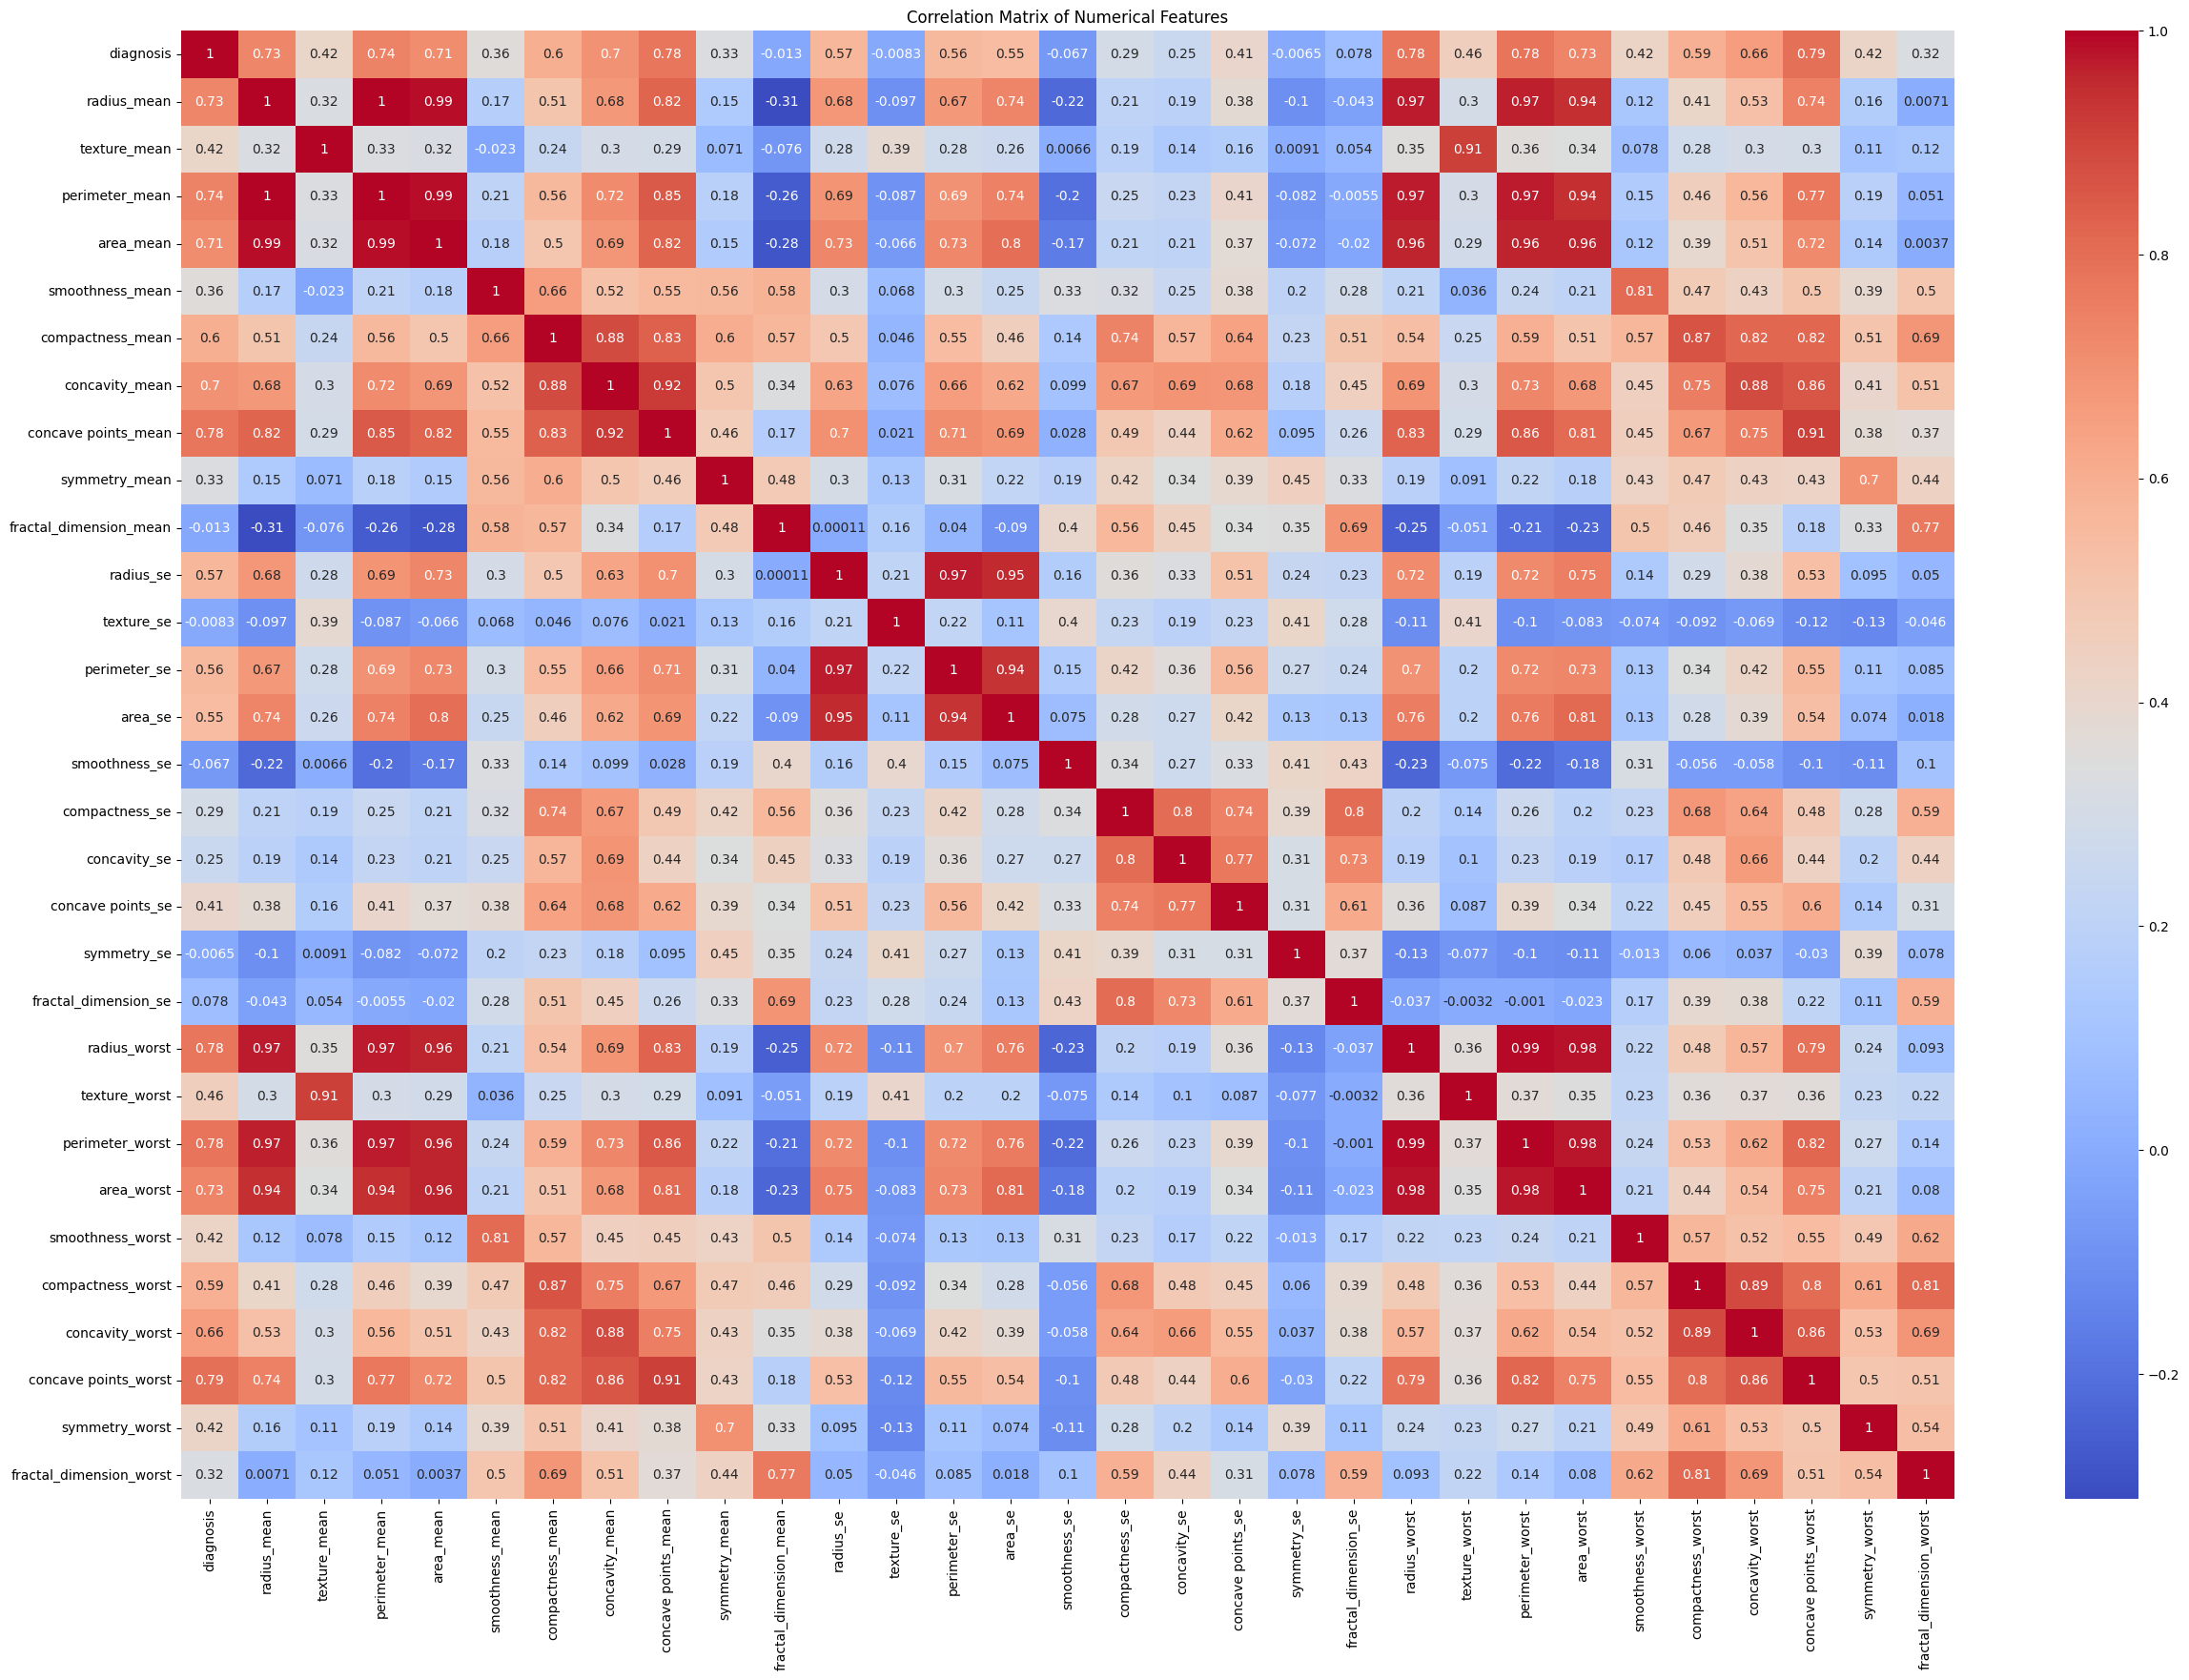

In [ ]:
# Select only numerical features for correlation analysis
numerical_features = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numerical_features.corr()

# Create a heatmap
plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

The dataset seems to have shomehow a linear correlation between each column and the target column.

## Pre Proccessing

Our task is to predict 'Diagnosis'.

First, let's split the dataset:

In [ ]:

from sklearn.model_selection import train_test_split

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### Normalization/Stadardization
we will normalize numerical columns to have a similar range.

It is important to split the dataset before normalization, to avoid any data leakage from test set into training set.


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Methods

## Linear Regression

First we try the most basic option: Logistic regression !

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

conf_matrix = confusion_matrix(y_test, y_pred)
print(classification_report(y_test , y_pred , digits=5))

              precision    recall  f1-score   support

           0    0.97222   0.98592   0.97902        71
           1    0.97619   0.95349   0.96471        43

    accuracy                        0.97368       114
   macro avg    0.97421   0.96970   0.97186       114
weighted avg    0.97372   0.97368   0.97362       114



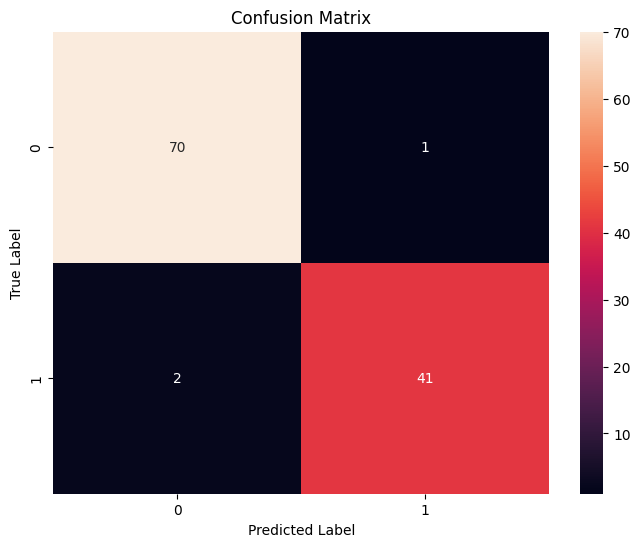

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## SVM

SVM Classifier Results:
              precision    recall  f1-score   support

           0    0.97143   0.95775   0.96454        71
           1    0.93182   0.95349   0.94253        43

    accuracy                        0.95614       114
   macro avg    0.95162   0.95562   0.95353       114
weighted avg    0.95649   0.95614   0.95624       114



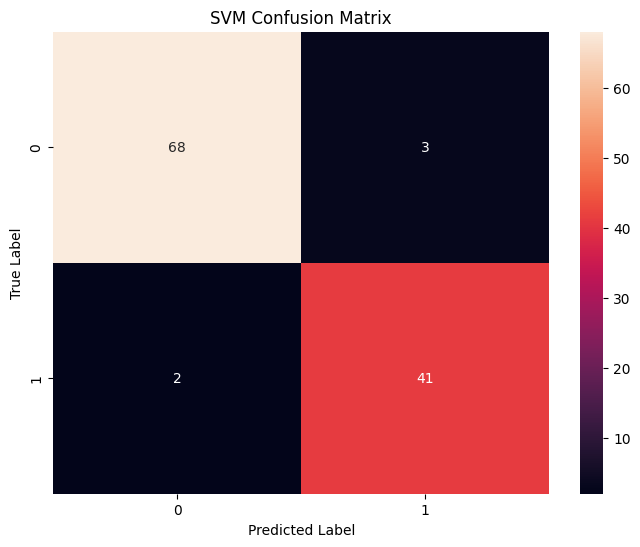

In [ ]:
from sklearn.svm import SVC

# Create an SVM classifier
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
print("SVM Classifier Results:")
print(classification_report(y_test, y_pred_svm, digits=5))

cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Best Parameters: {'C': 0.3, 'kernel': 'linear'}
Best F1-score: 0.9762842018312025
Best SVM Classifier Results:
              precision    recall  f1-score   support

           0    0.97222   0.98592   0.97902        71
           1    0.97619   0.95349   0.96471        43

    accuracy                        0.97368       114
   macro avg    0.97421   0.96970   0.97186       114
weighted avg    0.97372   0.97368   0.97362       114



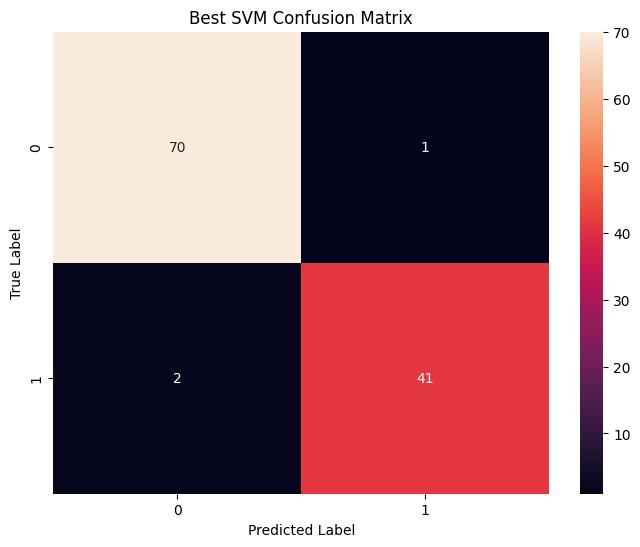

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 0.3, 0.7, 1.0, 3 ,5, 7, 10, 30,100],  # Regularization parameter
    'kernel': ['linear', 'rbf', 'poly'],  # Kernel type
}

svm_model = SVC()
grid_search = GridSearchCV(estimator=svm_model, param_grid=param_grid, cv=5, scoring='f1_macro')

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best F1-score:", grid_search.best_score_)

best_svm_model = grid_search.best_estimator_
y_pred_best_svm = best_svm_model.predict(X_test)

print("Best SVM Classifier Results:")
print(classification_report(y_test, y_pred_best_svm, digits=5))

cm_best_svm = confusion_matrix(y_test, y_pred_best_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best_svm, annot=True)
plt.title("Best SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

As it can be seen, the F1-score increases with this hyperparameter-tuning.

## Kernel SVM

In the previous section, we have done this part when we did hyperparameter tuning using grid search.

## KNN


We have two different weighting strategy: uniform and distance.
1. Uniform: Every neighbor in the neighborhood has equal weights.
2. Distance: The weight of each point in the neighborhood is proportional to the inverse of its distance from the target point.

Best KNN Parameters: {'n_neighbors': 7, 'weights': 'distance'}
Best KNN F1-score: 0.9591009106672782
Best KNN Classifier Results:
              precision    recall  f1-score   support

           0    0.95775   0.95775   0.95775        71
           1    0.93023   0.93023   0.93023        43

    accuracy                        0.94737       114
   macro avg    0.94399   0.94399   0.94399       114
weighted avg    0.94737   0.94737   0.94737       114



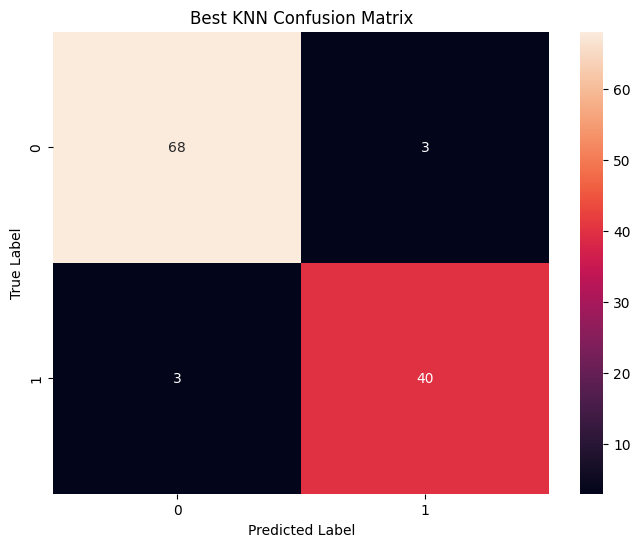

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],  # Number of neighbors to consider
    'weights': ['uniform', 'distance'],  # Weighting strategy for neighbors
}

# Create a KNN classifier
knn_model = KNeighborsClassifier()

grid_search_knn = GridSearchCV(estimator=knn_model, param_grid=param_grid_knn, cv=5, scoring='f1_macro')
grid_search_knn.fit(X_train, y_train)

# Print the best parameters and the corresponding F1-score
print("Best KNN Parameters:", grid_search_knn.best_params_)
print("Best KNN F1-score:", grid_search_knn.best_score_)

# Train the KNN model with the best parameters
best_knn_model = grid_search_knn.best_estimator_
y_pred_knn = best_knn_model.predict(X_test)

# Evaluate the best KNN model
print("Best KNN Classifier Results:")
print(classification_report(y_test, y_pred_knn, digits=5))

# Plot the confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True)
plt.title("Best KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

This classifer is performing poorer than two previous models, since those methods pay attention to the features and assign suitable weights to each of them. But, KNN maps each point to d-dimensional features and use 'neighborhoods' and 'distances' as measurements.

## Decision Tree

Decision Tree Classifier Results:
              precision    recall  f1-score   support

           0  0.957746479 0.957746479 0.957746479        71
           1  0.930232558 0.930232558 0.930232558        43

    accuracy                      0.947368421       114
   macro avg  0.943989519 0.943989519 0.943989519       114
weighted avg  0.947368421 0.947368421 0.947368421       114



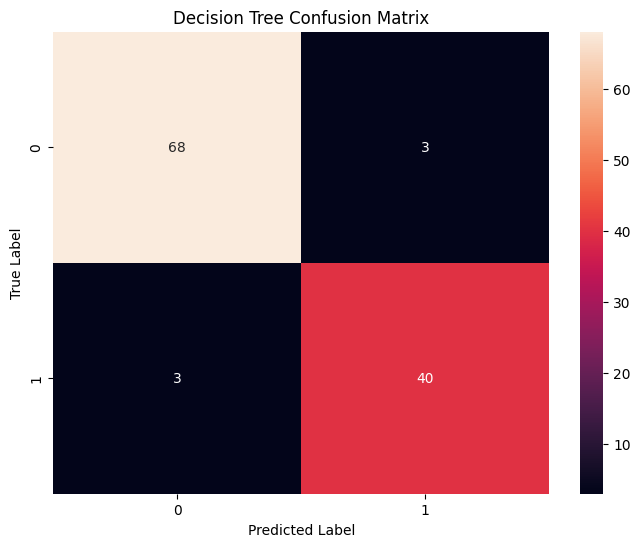

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create a Decision Tree classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Classifier Results:")
print(classification_report(y_test, y_pred_dt, digits=9))

# Plot the confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


Best Decision Tree Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'random_state': 42}
Best Decision Tree F1-score: 0.9387848203731736
Best Decision Tree Classifier Results:
              precision    recall  f1-score   support

           0  0.946666667 1.000000000 0.972602740        71
           1  1.000000000 0.906976744 0.951219512        43

    accuracy                      0.964912281       114
   macro avg  0.973333333 0.953488372 0.961911126       114
weighted avg  0.966783626 0.964912281 0.964537136       114



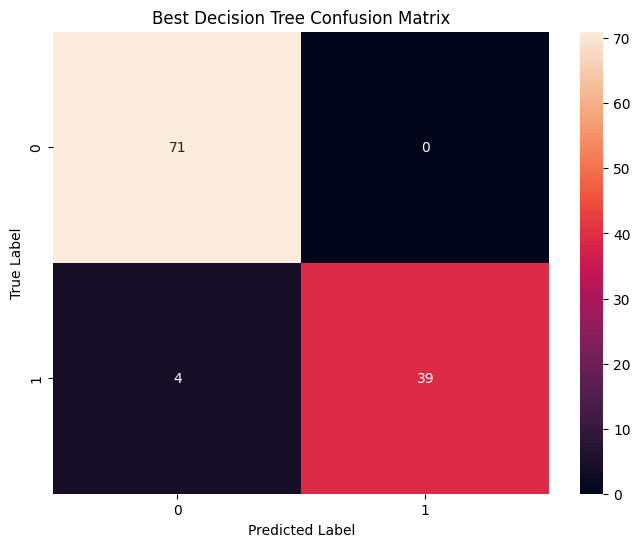

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for Decision Tree
param_grid_dt = {
    'random_state': [42],
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(3, 16)),
    'min_samples_split': [2, 5,7, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Decision Tree classifier
dt_model = DecisionTreeClassifier()

# Perform GridSearchCV to find the best hyperparameters
grid_search_dt = GridSearchCV(estimator=dt_model, param_grid=param_grid_dt, cv=5, scoring='f1_macro')
grid_search_dt.fit(X_train, y_train)

# Print the best parameters and the corresponding F1-score
print("Best Decision Tree Parameters:", grid_search_dt.best_params_)
print("Best Decision Tree F1-score:", grid_search_dt.best_score_)

# Train the Decision Tree model with the best parameters
best_dt_model = grid_search_dt.best_estimator_
y_pred_dt = best_dt_model.predict(X_test)

# Evaluate the best Decision Tree model
print("Best Decision Tree Classifier Results:")
print(classification_report(y_test, y_pred_dt, digits=9))

# Plot the confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True)
plt.title("Best Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Random forest

Random Forest Classifier Results:
              precision    recall  f1-score   support

           0  0.958904110 0.985915493 0.972222222        71
           1  0.975609756 0.930232558 0.952380952        43

    accuracy                      0.964912281       114
   macro avg  0.967256933 0.958074026 0.962301587       114
weighted avg  0.965205362 0.964912281 0.964738234       114



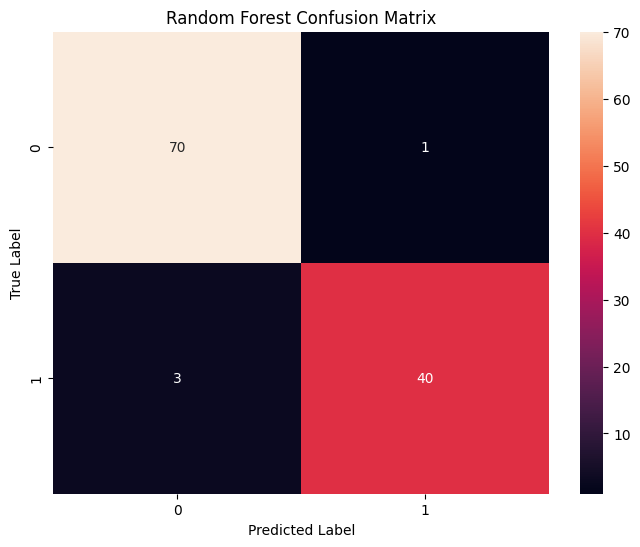

In [ ]:
# prompt: Random forest

from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Classifier Results:")
print(classification_report(y_test, y_pred_rf, digits=9))

# Plot the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Best Random Forest Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200, 'random_state': 42}
Best Random Forest F1-score: 0.9596714088434176
Best Random Forest Classifier Results:
              precision    recall  f1-score   support

           0  0.958904110 0.985915493 0.972222222        71
           1  0.975609756 0.930232558 0.952380952        43

    accuracy                      0.964912281       114
   macro avg  0.967256933 0.958074026 0.962301587       114
weighted avg  0.965205362 0.964912281 0.964738234       114



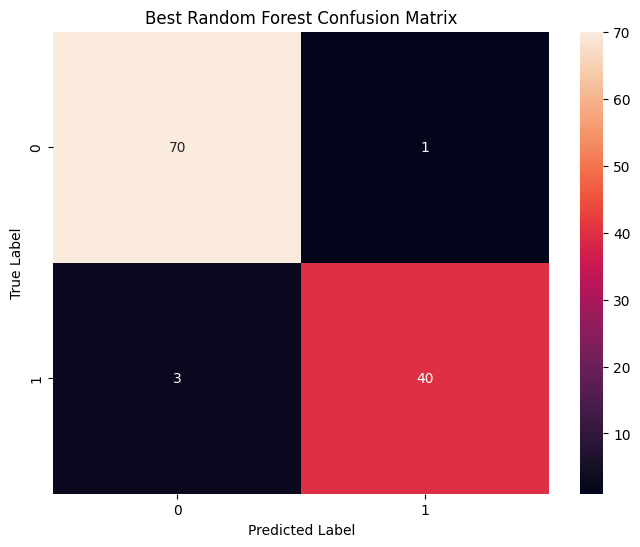

In [ ]:

# Define the parameter grid for Random Forest
param_grid_rf = {
    'random_state': [42],
    'n_estimators': [50, 100,150, 200],  # Number of trees in the forest
    'max_depth': [None, 3, 5, 10, 20],  # Maximum depth of the tree
    'min_samples_split': [2, 5, 7, 10],  # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4]  # Minimum number of samples required to be at a leaf node
}

# Create a Random Forest classifier
rf_model = RandomForestClassifier(random_state=42)

# Perform GridSearchCV to find the best hyperparameters
grid_search_rf = GridSearchCV(estimator=rf_model, param_grid=param_grid_rf, cv=5, scoring='f1_macro')
grid_search_rf.fit(X_train, y_train)

# Print the best parameters and the corresponding F1-score
print("Best Random Forest Parameters:", grid_search_rf.best_params_)
print("Best Random Forest F1-score:", grid_search_rf.best_score_)

# Train the Random Forest model with the best parameters
best_rf_model = grid_search_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)

# Evaluate the best Random Forest model
print("Best Random Forest Classifier Results:")
print(classification_report(y_test, y_pred_rf, digits=9))

# Plot the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True)
plt.title("Best Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# regularization techniques
1. **Restricting Tree Depth**

* Limiting the maximum depth of the tree prevents it from growing too complex and overfitting the training data.
* How It Works:
A shallow tree forces the model to generalize better by considering only the most important splits.


2.  **Minimum Samples per Split or Leaf**
* Restricting the minimum number of samples required to split a node or to be present in a leaf node reduces overfitting by ensuring splits are statistically meaningful.
* How It Works:
A higher `min_samples_spli`t prevents splitting nodes with very few samples.
A higher `min_samples_leaf` ensures leaf nodes contain more samples, which reduces sensitivity to noise.



3. **Maximum Features for Splitting**
* Restricting the number of features considered for a split (at each node) introduces randomness, reducing the likelihood of overfitting.
* How It Works:
At each split, a random subset of features is chosen, and the best split is determined only from this subset.
This is commonly used in ensemble methods like Random Forests but can also be applied to individual decision trees.
